# Evaluator: novelty-based visibility selection strength

**Source simulation:** `Visibility_dissimilarity_selection(4).py` (novelty/dissimilarity-based selection). The experiment holds visibility **extent at 1.0** and provides **exactly 20 sender-solution entries per recipient** every **10 search periods**. Selection strength controls the share selected by **novelty (largest Hamming distance)** from a recipient's current configuration; the remaining entries are randomly drawn from the other sender entries.

- `novelty_selection_strength = 0.0`: **20 random recommendations** (random-selection benchmark; **not search-apart**).
- `novelty_selection_strength = 1.0`: **20 most novel sender entries**.
- Intermediate values `0.2, 0.4, 0.6, 0.8` prioritize **4, 8, 12, 16** entries, respectively; random entries complete the fixed pool of 20.

All seven outcomes refer to the **recipient crowd**. Lower breakthrough solution ranks indicate better discovery. Pairwise diversity measures normalized Hamming distance; adoption quality reflects **true NK fitness** of adopted solutions. The new **generative potential** metric is calculated from sampled successful adoptions through independent post-adoption search continuations (`generative_horizon=30`, `generative_replications=30`, `generative_sample_size=5`); its exact definition resides in `Crowd.calculate_generative_potential`. The figures equally average outcomes across `K=9..17`.

The script uses **600 landscapes × 10 solver resets** per `(selection strength, K)` before saving the aggregated means. These pickle files contain aggregate results, not individual-run observations.

In [6]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91', '#637A3D']


def format_axis(ax):
    """Keep the formatting of the provided evaluator."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [7]:
# =========================
# Experiment configuration — Visibility_dissimilarity_selection(4).py
# =========================
N = 18
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 600  # Documentation only; aggregation takes place in the simulation.
solver_reset_num = 10      # Documentation only; independent solver resets share each landscape.
search_iteration = 300
K_list = list(range(9, N))
visibility_extent = 1.0
recommendation_num = 20
novelty_selection_strength_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
visibility_interval = 10

generative_horizon = 30       # Additional local-search opportunities per continuation.
generative_replications = 30  # Independent continuations per sampled adoption.
generative_sample_size = 5    # Reservoir-sampled successful adoptions per run.

# Use the directory containing the six sets of simulation pickle files.
# Set to your experiment output directory if pickles are not in the working directory.
# None searches the working directory and the common local subfolders listed below.
result_folder = r"/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Selection_fixed_num_20/Dissimilarity_based"

# Set to False to review results without saving figures.
save_figures = True
strict_loading = True  # Set False to inspect valid partial results from an unfinished run.

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (
    f'visibility_novelty_selection_strength_{novelty_selection_strength_list[0]}'
    f'_recommendation_num_{recommendation_num}_interval_{visibility_interval}'
    f'_breakthrough_rank_across_K_size_{agent_num}'
)

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_novelty_selection_strength_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

# All six settings are shown. No values are omitted from figures.
x = np.asarray(novelty_selection_strength_list, dtype=float)
priority_counts = [int(round(strength * recommendation_num))
                   for strength in novelty_selection_strength_list]
print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Folder exists:', result_folder.exists())
print('Novelty-prioritized recommendations per treatment:', dict(zip(novelty_selection_strength_list, priority_counts)))

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Selection_fixed_num_20/Dissimilarity_based
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Selection_fixed_num_20/Dissimilarity_based/visibility_novelty_selection_strength_figures
Example expected file: visibility_novelty_selection_strength_0.0_recommendation_num_20_interval_10_breakthrough_rank_across_K_size_100
Folder exists: True
Novelty-prioritized recommendations per treatment: {0.0: 0, 0.2: 4, 0.4: 8, 0.6: 12, 0.8: 16, 1.0: 20}


## 2. Load and validate the seven outcome families

For each treatment and outcome, the simulation writes a pickle using the exact pattern:

`visibility_novelty_selection_strength_{strength}_recommendation_num_{number}_interval_{interval}_{DV}_across_K_size_{agent_num}`

Six scalar outcomes have shape `(novelty selection strength, K)`, including the new `generative_potential`. The cumulative adoption-quality trajectory has shape `(novelty selection strength, K, visibility event)`. The loader checks **all six strengths**, **nine values of `K`**, and **30 visibility events**. In non-strict mode, missing or malformed results remain `NaN` rather than being replaced by zeros.

In [8]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
    'generative_potential',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
expected_events = search_iteration // visibility_interval


def result_file(strength, dv):
    filename = (
        f'visibility_novelty_selection_strength_{strength}'
        f'_recommendation_num_{recommendation_num}_interval_{visibility_interval}'
        f'_{dv}_across_K_size_{agent_num}'
    )
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_novelty_results(strict=True):
    n_strength = len(novelty_selection_strength_list)
    n_K = len(K_list)
    data = {dv: np.full((n_strength, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_strength, n_K, expected_events), np.nan)
    missing_files = []
    invalid_files = []

    for i, strength in enumerate(novelty_selection_strength_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(strength, dv)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, EOFError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, expected_events) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            data[dv][i] = values

    n_expected = n_strength * (len(scalar_dvs) + 1)  # Six scalar DVs plus one trajectory DV.
    print(f'Files loaded: {n_expected - len(missing_files) - len(invalid_files)} / {n_expected}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid selection-strength results. Check result_folder, agent_num, '
            'recommendation_num, visibility_interval, and novelty_selection_strength_list; '
            'or set strict_loading=False for incomplete runs. First expected file: '
            + str(result_file(novelty_selection_strength_list[0], 'breakthrough_rank'))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_visibility_novelty_results(strict=strict_loading)

Files loaded: 42 / 42
Array shapes: {'breakthrough_rank': (6, 9), 'breakthrough_fitness': (6, 9), 'pairwise_diversity': (6, 9), 'unique_solution_count': (6, 9), 'adopted_solution_fitness': (6, 9), 'generative_potential': (6, 9), 'adopted_solution_fitness_across_time': (6, 9, 30)}


In [9]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# The new generative-potential measure is checked for coverage but not constrained
# to an assumed interval; its scale is defined in Crowd.calculate_generative_potential.
print('generative_potential'.ljust(29),
      f"finite={np.isfinite(data['generative_potential']).sum():3d} / {data['generative_potential'].size:3d}")

# The trajectory's final cumulative mean should match the scalar adoption-quality
# measure for each (novelty_selection_strength, K), up to floating-point differences.
last_trajectory = data[trajectory_dv][:, :, -1]
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, strength in enumerate(novelty_selection_strength_list):
    for j, K in enumerate(K_list):
        row = {'novelty_selection_strength': strength, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per novelty selection strength × K):')
# display(detailed_results.head(12).round(4))

breakthrough_rank             finite= 54 /  54; outside expected range=0
breakthrough_fitness          finite= 54 /  54; outside expected range=0
pairwise_diversity            finite= 54 /  54; outside expected range=0
unique_solution_count         finite= 54 /  54; outside expected range=0
adopted_solution_fitness      finite= 54 /  54; outside expected range=0
generative_potential          finite= 54 /  54
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per novelty selection strength × K):


## 3. Main outcomes across novelty selection strength

Each figure displays all six treatments, from **random recommendations** (`0.0`) to fully **novelty-prioritized recommendations** (`1.0`). The recommendation pool always contains **20 entries**, so the horizontal axis measures **selection strength**, not visibility extent. Overall curves give equal weight to `K=9..17`; the adjacent plots retain each `K` separately. In this experiment, prioritization uses **novelty (largest Hamming distance)** relative to the recipient's current configuration.

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Selection_fixed_num_20/Dissimilarity_based/visibility_novelty_selection_strength_figures/Breakthrough_across_novelty_selection_strength.png


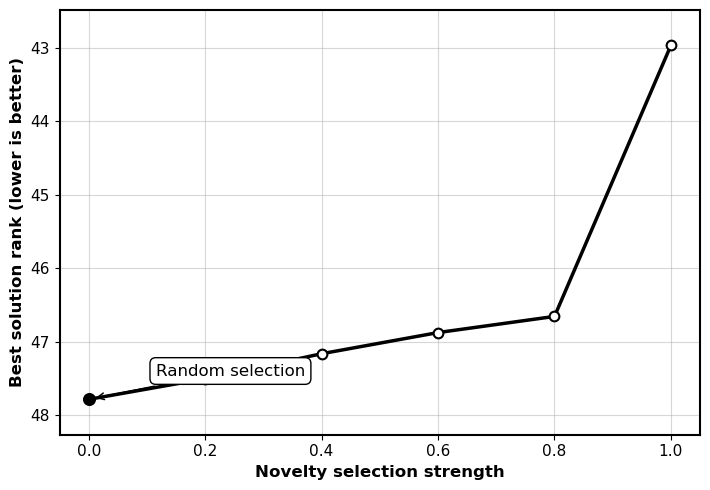

In [10]:
# =========================
# Best solution rank across novelty selection strength (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(novelty_selection_strength_list)
y_rank = safe_nanmean(data["breakthrough_rank"], axis=1)

# Identify random-selection benchmark point
zero_idx = 0
zero_x, zero_y = x[zero_idx], y_rank[zero_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y_rank,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.margins(x=0.05, y=0.10)

# Highlight random-selection benchmark
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Random-selection annotation
# -------------------------
ax.annotate(
    "Random selection",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.15, 0.15),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.invert_yaxis()  # Rank 1 is best; invert so a better rank is visually higher.
ax.set_xticks(x)

ax.set_xlabel(
    "Novelty selection strength",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Best solution rank (lower is better)",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

if save_figures:
    output_png = figure_folder / "Breakthrough_across_novelty_selection_strength.png"

    plt.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )

    print("Saved:", output_png)

plt.show()

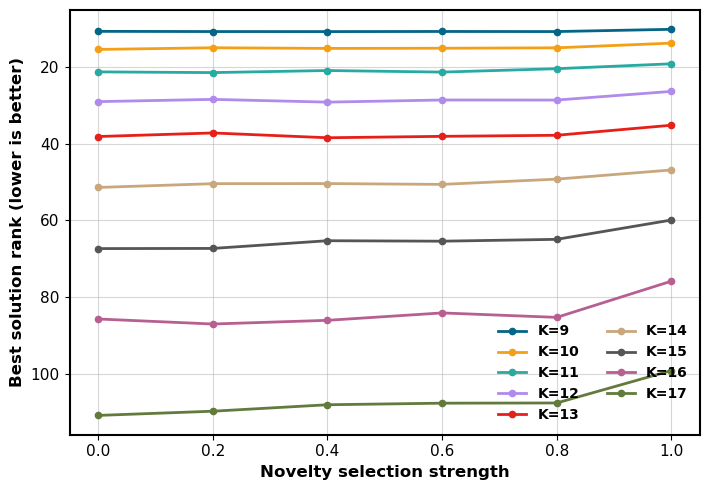

In [11]:
# Best solution rank across novelty selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['breakthrough_rank'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xticks(x)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_by_K_across_novelty_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Change_Orientation_Measure/Selection_fixed_num_20/Dissimilarity_based/visibility_novelty_selection_strength_figures/Pairwise_diversity_across_novelty_selection_strength.png


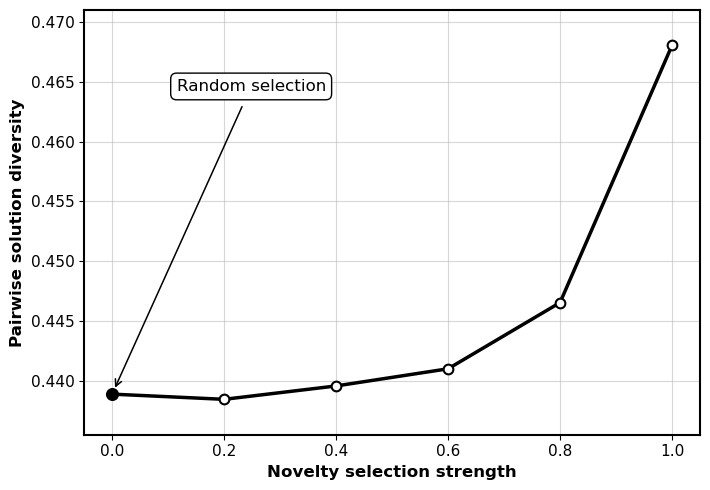

In [12]:
# =========================
# Pairwise diversity across novelty selection strength (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(novelty_selection_strength_list)
y_diversity = safe_nanmean(data["pairwise_diversity"], axis=1)

# Identify random-selection benchmark point
zero_idx = 0
zero_x, zero_y = x[zero_idx], y_diversity[zero_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y_diversity,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.margins(x=0.05, y=0.10)

# Highlight random-selection benchmark
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Random-selection annotation
# -------------------------
ax.annotate(
    "Random selection",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.15, 0.82),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.set_xticks(x)

ax.set_xlabel(
    "Novelty selection strength",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Pairwise solution diversity",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

if save_figures:
    output_png = figure_folder / "Pairwise_diversity_across_novelty_selection_strength.png"

    plt.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )

    print("Saved:", output_png)

plt.show()

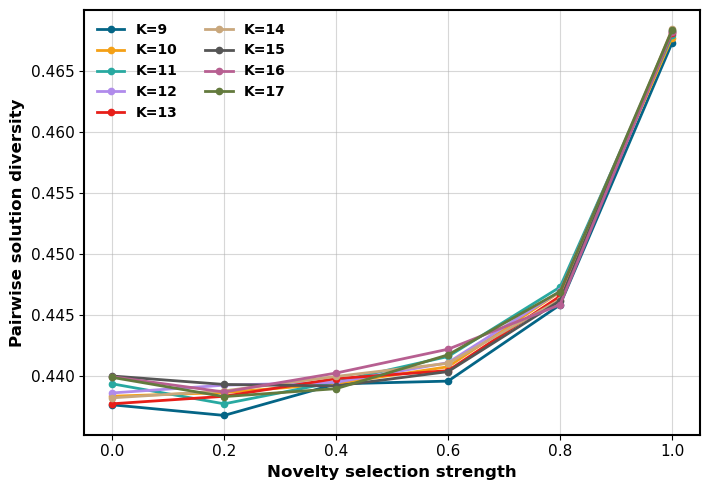

In [13]:
# Pairwise diversity across novelty selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['pairwise_diversity'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(x)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_by_K_across_novelty_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

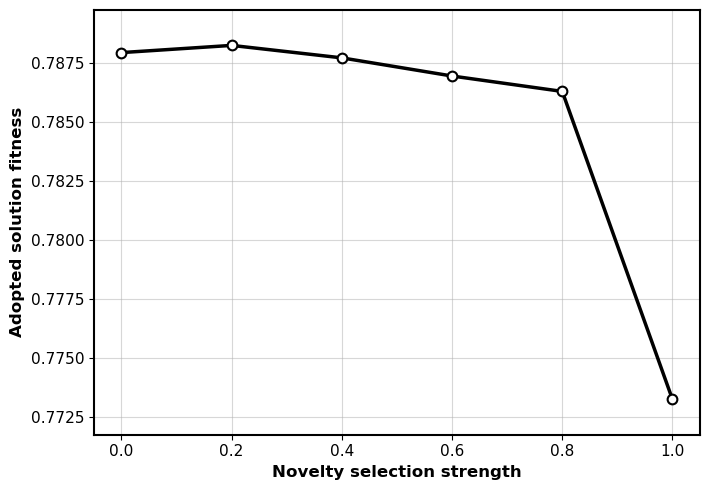

In [14]:
# Adopted solution fitness across novelty selection strength (average across K).
# At strength=0, recipients still see 20 random sender entries, so adoption quality is defined
# whenever at least one sender solution is adopted.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)

y_adopted = safe_nanmean(data['adopted_solution_fitness'], axis=1)
valid = np.isfinite(y_adopted)

ax.plot(x[valid], y_adopted[valid], marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)

ax.set_xticks(x)
ax.margins(x=0.05, y=0.10)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)

fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_across_novelty_selection_strength.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

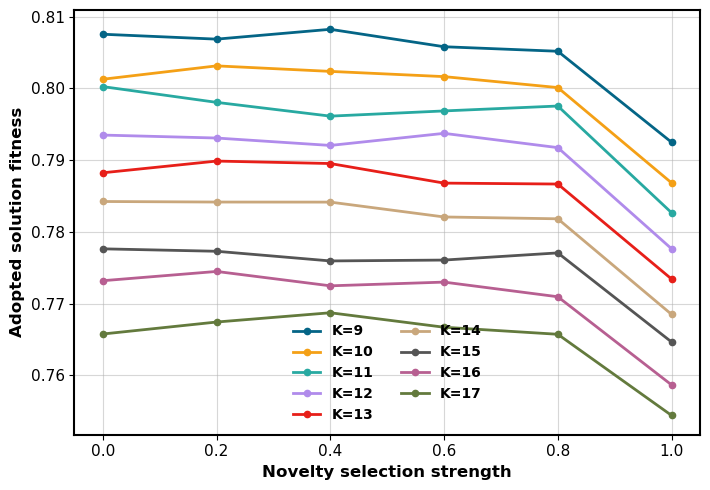

In [15]:
# Adopted solution fitness across novelty selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['adopted_solution_fitness'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(x)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_novelty_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Generative potential (new outcome)

The updated simulation additionally saves `generative_potential_across_K`, measured using independent continuation searches from sampled successful adoptions. The following figures **match the existing outcome-plotting format**: a black line with hollow circular markers for the equal-weight `K` average and a colored line for each `K`. A corresponding heatmap appears in the final section. Missing potential values remain undefined (`NaN`).

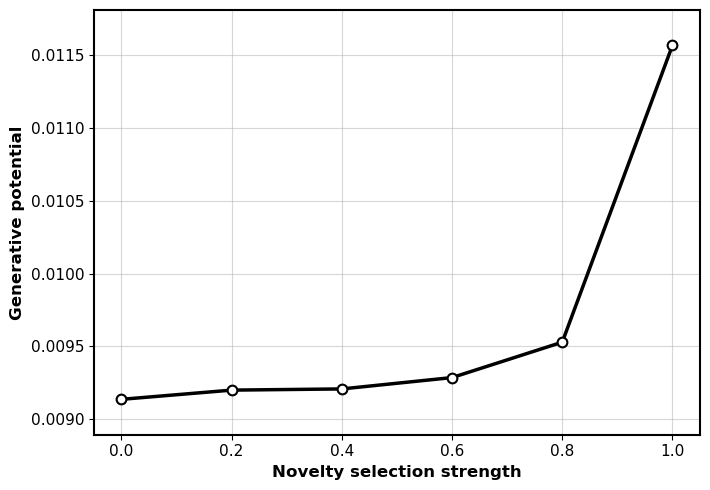

In [16]:
# Generative potential across novelty selection strength (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)

y_generative = safe_nanmean(data['generative_potential'], axis=1)
valid = np.isfinite(y_generative)

ax.plot(x[valid], y_generative[valid], marker='o', linewidth=2.5,
        markersize=7, color='k', markerfacecolor='white',
        markeredgecolor='black', markeredgewidth=1.5)

ax.set_xticks(x)
ax.margins(x=0.05, y=0.10)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Generative potential', fontweight='bold', fontsize=12)

fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Generative_potential_across_novelty_selection_strength.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

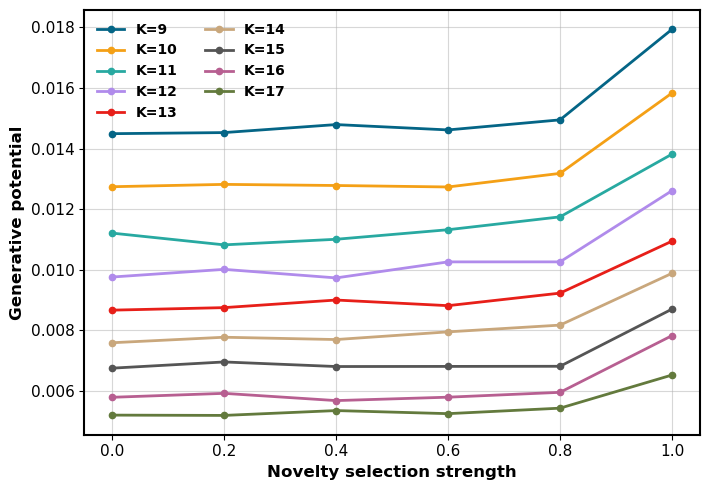

In [17]:
# Generative potential across novelty selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['generative_potential'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(x)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Generative potential', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Generative_potential_by_K_across_novelty_selection_strength.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Additional outcomes

`breakthrough_fitness` records the best final recipient fitness, whereas `breakthrough_rank` records the corresponding best solution rank on the NK landscape. `unique_solution_count` counts distinct final recipient solutions, while normalized `pairwise_diversity` captures how far the solutions differ. Neither diversity measure changes the fixed recommendation count.

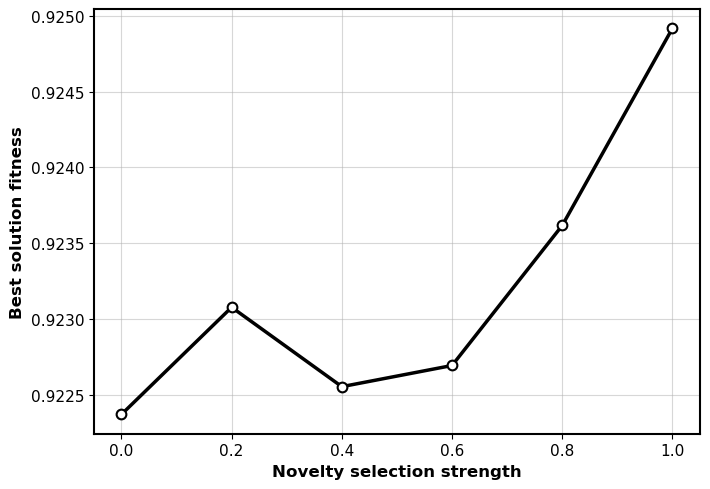

In [18]:
# Best solution fitness across novelty selection strength (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_fitness = safe_nanmean(data['breakthrough_fitness'], axis=1)
ax.plot(x, y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(x)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Best_solution_fitness_across_novelty_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

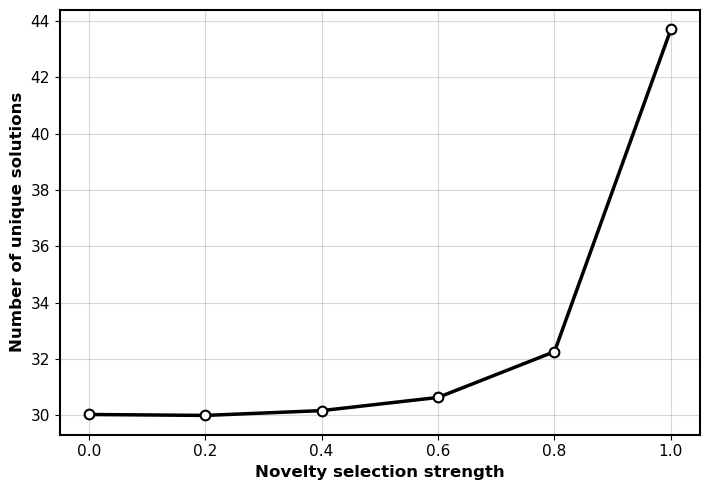

In [19]:
# Unique solution count across novelty selection strength (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_unique = safe_nanmean(data['unique_solution_count'], axis=1)
ax.plot(x, y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(x)
ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Unique_solution_count_across_novelty_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Cumulative adoption-quality trajectories

Set `trajectory_novelty_selection_strength` to any of the six simulated strengths. The horizontal axis gives visibility-event periods (`10, 20, ..., 300`). Each value is the **cumulative mean true fitness of adopted sender solutions through that event**, rather than the mean fitness of all recipient solutions or adoptions in only that period. Unlike a search-apart condition, the `0.0` random-selection condition can have a valid adoption-fitness trajectory.

In [20]:
trajectory_novelty_selection_strength = 1.0  # Any entry in novelty_selection_strength_list.
if trajectory_novelty_selection_strength not in novelty_selection_strength_list:
    raise ValueError('trajectory_novelty_selection_strength must appear in novelty_selection_strength_list.')
trajectory_index = novelty_selection_strength_list.index(trajectory_novelty_selection_strength)
trajectory_periods = np.arange(1, expected_events + 1) * visibility_interval
trajectory_by_K = data[trajectory_dv][trajectory_index]  # (K, visibility event)
print('Trajectory novelty selection strength:', trajectory_novelty_selection_strength)
print('Visibility events:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory novelty selection strength: 1.0
Visibility events: 30 | last search period: 300
Defined trajectory entries: 270 / 270


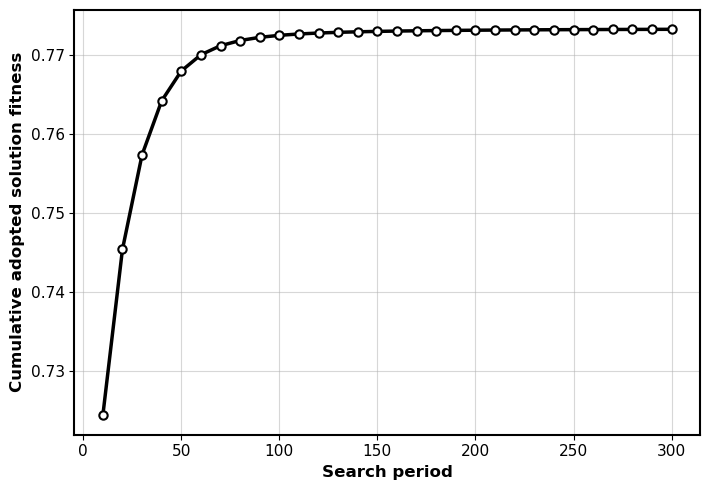

In [21]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_novelty_selection_strength_{trajectory_novelty_selection_strength:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

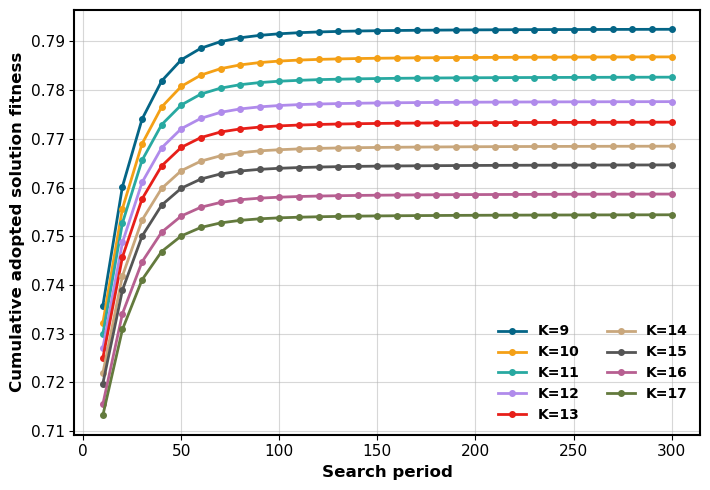

In [22]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_novelty_selection_strength_{trajectory_novelty_selection_strength:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 7. Novelty selection strength × landscape complexity

Heatmaps show **all six novelty selection-strength treatments** and each `K` separately. The `0.0` treatment is **random selection**, not search-apart. The prioritization criterion is **novelty (largest Hamming distance)**, rather than fitness rank; breakthrough ranks remain an outcome measure. Undefined adoption-quality or generative-potential cells are kept as missing values. The new generative-potential heatmap uses the same layout and palette as the existing outcomes.

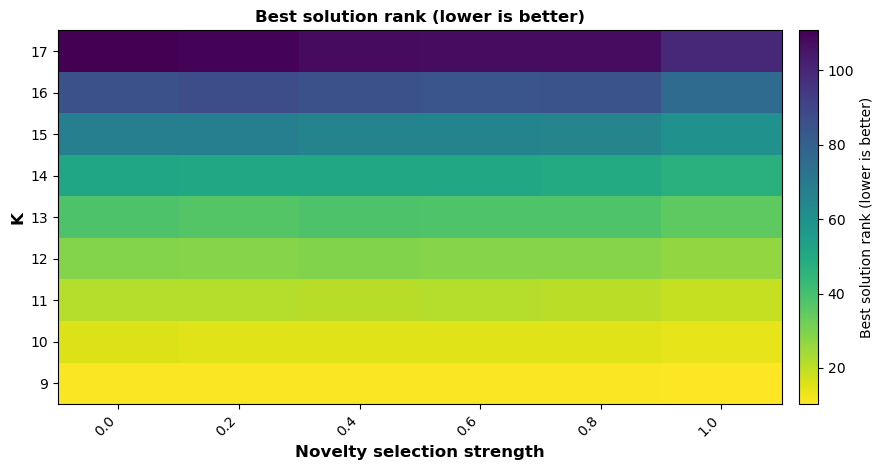

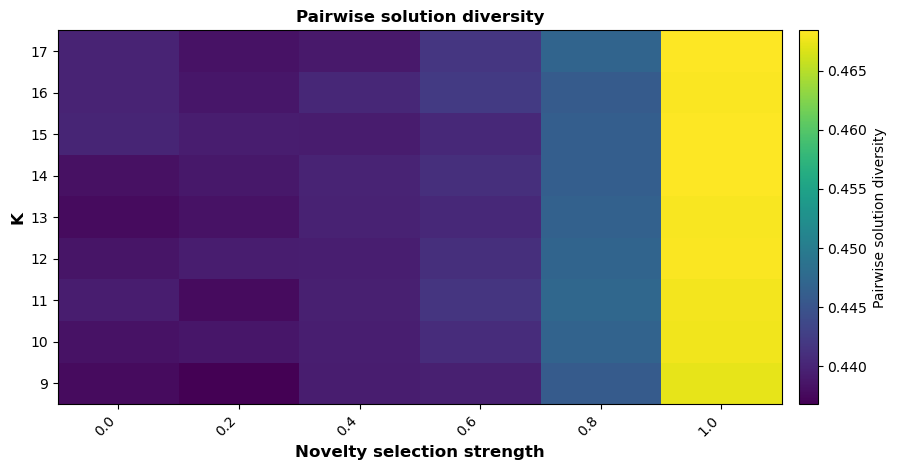

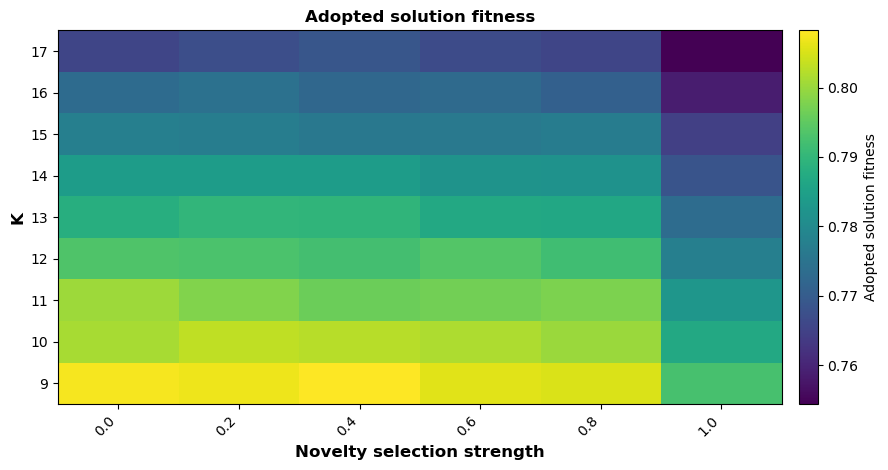

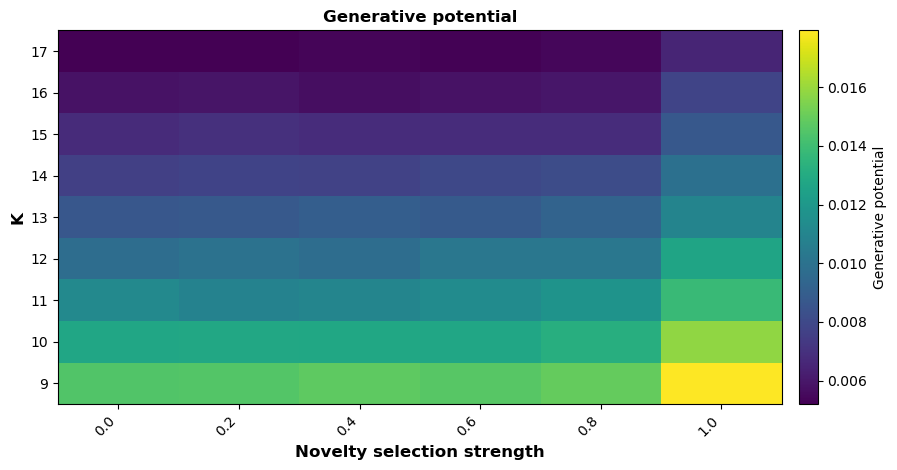

In [23]:
for dv, title, filename, cmap in [
    ('breakthrough_rank', 'Best solution rank (lower is better)', 'Best_solution_rank_heatmap_across_novelty_selection_strength_and_K.png', 'viridis_r'),
    ('pairwise_diversity', 'Pairwise solution diversity', 'Pairwise_diversity_heatmap_across_novelty_selection_strength_and_K.png', 'viridis'),
    ('adopted_solution_fitness', 'Adopted solution fitness', 'Adopted_solution_fitness_heatmap_across_novelty_selection_strength_and_K.png', 'viridis'),
    ('generative_potential', 'Generative potential', 'Generative_potential_heatmap_across_novelty_selection_strength_and_K.png', 'viridis'),
]:
    values = np.ma.masked_invalid(data[dv].T)  # (K, displayed novelty selection strength)
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(novelty_selection_strength_list)))
    ax.set_xticklabels([f'{ratio:.1f}' for ratio in novelty_selection_strength_list], rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Novelty selection strength', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    fig.tight_layout()
    # if save_figures:
    #     fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()